In [53]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

data=fetch_olivetti_faces()
X=data.images
Y=data.target

print(X.shape)

(400, 64, 64)


# Сжатие до 32

#### Если делать делать до 2, то при восстановлении все лица будут одинаковые

In [54]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2)
latent_dim=32

### Encoder

In [55]:
modelEnc=tf.keras.models.Sequential(name='Encoder')
modelEnc.add(tf.keras.layers.Input(shape=(64,64)))
modelEnc.add(tf.keras.layers.Reshape((64,64,1)))
modelEnc.add(tf.keras.layers.Conv2D(16, kernel_size=3, padding='same',strides=2, activation='selu'))
modelEnc.add(tf.keras.layers.Conv2D(32, kernel_size=3, padding='same',strides=2, activation='selu'))
modelEnc.add(tf.keras.layers.Conv2D(64, kernel_size=3, padding='same',strides=2, activation='selu'))
modelEnc.add(tf.keras.layers.Conv2D(128, kernel_size=3, padding='same',strides=2, activation='selu'))
modelEnc.add(tf.keras.layers.Flatten())
modelEnc.add(tf.keras.layers.Dense(latent_dim,activation='linear'))

# tf.keras.utils.plot_model(modelEnc, show_layer_activations=True, show_shapes=True)

### Decoder

In [56]:
modelDec=tf.keras.models.Sequential(name='Decoder')
modelDec.add(tf.keras.layers.Input(shape=(latent_dim,)))
modelDec.add(tf.keras.layers.Reshape((1,1,latent_dim)))
modelDec.add(tf.keras.layers.Conv2DTranspose(128, kernel_size=3, strides=2, padding="same", activation="selu"))
modelDec.add(tf.keras.layers.Conv2DTranspose(128, kernel_size=3, strides=2, padding="same", activation="selu"))
modelDec.add(tf.keras.layers.Conv2DTranspose(64, kernel_size=3, strides=2, padding="same", activation="selu"))
modelDec.add(tf.keras.layers.Conv2DTranspose(32, kernel_size=3, strides=2, padding="same", activation="selu"))
modelDec.add(tf.keras.layers.Conv2DTranspose(16, kernel_size=3, strides=2, padding="same", activation="selu"))
modelDec.add(tf.keras.layers.Conv2DTranspose(1, kernel_size=3, strides=2, padding="same", activation="sigmoid"))
modelDec.add(tf.keras.layers.Reshape((64, 64)))

# tf.keras.utils.plot_model(modelDec, show_layer_activations=True, show_shapes=True)

### AutoEncoder

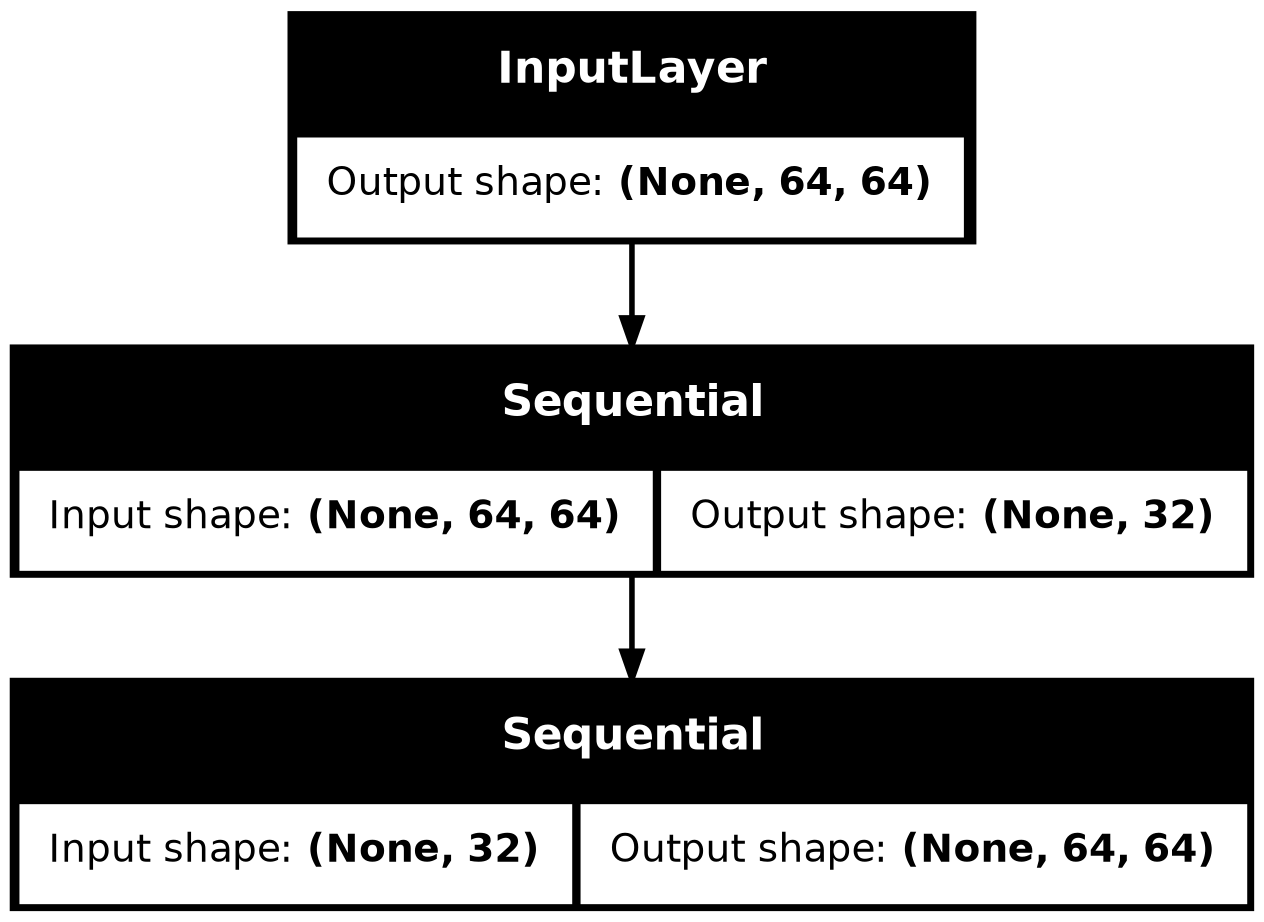

In [57]:
x=tf.keras.layers.Input(shape=(64,64))
y=modelEnc(x)
out=modelDec(y)

autoencoder=tf.keras.models.Model(inputs=[x],outputs=[out])

tf.keras.utils.plot_model(autoencoder, show_layer_activations=True, show_shapes=True)


In [58]:
autoencoder.compile(optimizer='adam',loss='mse')
es=tf.keras.callbacks.EarlyStopping(monitor='val_loss',mode='min',patience=15,restore_best_weights=True)
autoencoder.fit(x_train,x_train,epochs=1000,validation_split=0.2,callbacks=[es])

Epoch 1/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0283 - val_loss: 0.0229
Epoch 2/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0219 - val_loss: 0.0206
Epoch 3/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0203 - val_loss: 0.0186
Epoch 4/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0190 - val_loss: 0.0178
Epoch 5/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0171 - val_loss: 0.0149
Epoch 6/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0151 - val_loss: 0.0136
Epoch 7/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0130 - val_loss: 0.0123
Epoch 8/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0119 - val_loss: 0.0121
Epoch 9/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0112 - val_loss: 0.0103
Epoch 10/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0101 - val_loss: 0.0096
Epoch 11/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0094 - val_loss: 0.0091
Epoch 12/1000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0

## Распределение эмбеддингов в бутылочном горлышке

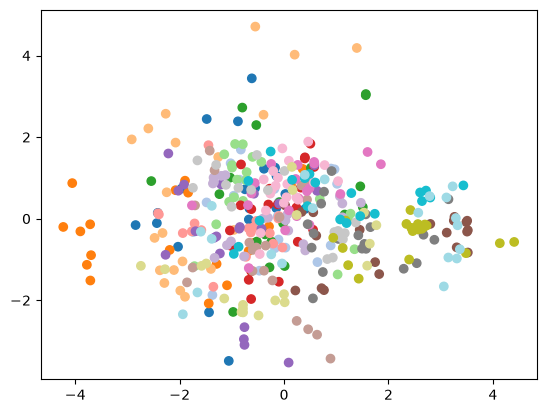

In [59]:
from sklearn.decomposition import PCA
y = modelEnc(X)
clf = PCA(n_components=2)
clf_fit = clf.fit_transform(y)
plt.scatter(clf_fit[:,0],clf_fit[:,1],c=Y,cmap="tab20")

## Примеры восстановления

/home/permak07/Documents/study/course2/Data_Analysis/.venv/lib/python3.12/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_382']
Received: inputs=Tensor(shape=(400, 64, 64))
  warnings.warn(msg)


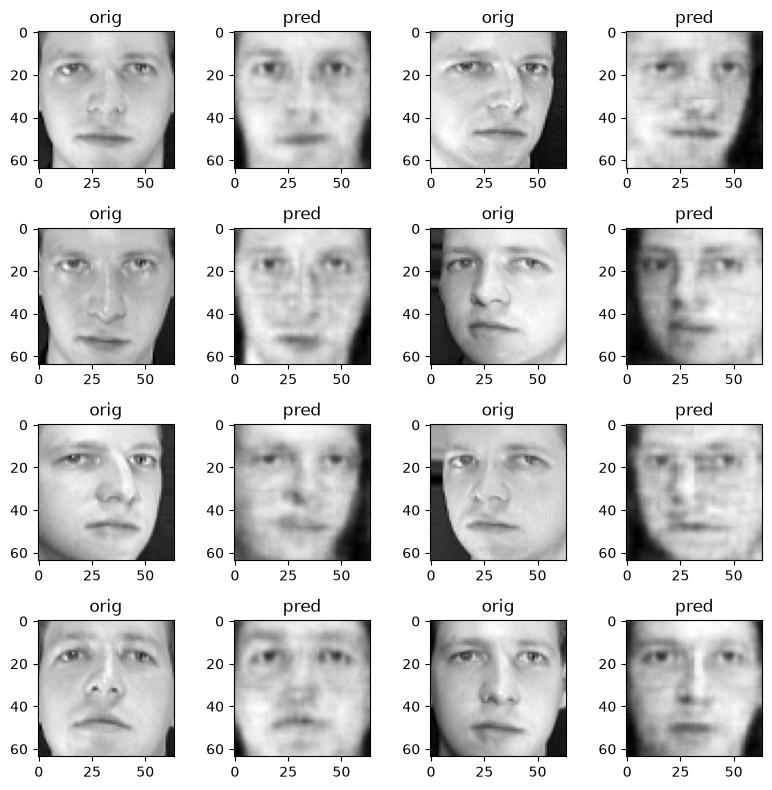

In [60]:
Xp=autoencoder(X)
plt.figure(figsize=(8, 8))
for i in range(8):
    plt.subplot(4,4,2*i+1)
    plt.title('orig')
    plt.imshow(X[i],cmap='gray')
    plt.subplot(4,4,2*i+2)
    plt.title('pred')
    plt.imshow(Xp[i],cmap='gray')

plt.tight_layout()